# Model 2: FMBCNN with skip connections: CNN denoiser (step 1 of 2)

Trains the CNN and saves the best version to `SAVE_DIR`. Run the matching **GAN notebook** afterwards.

Cells from the top down to *Load data* and the helper cell are identical in every notebook. Only the model cell and the hyperparameter grid differ per model.

**Changes from the original:** one checkpoint per hyperparameter setting (the old code overwrote one file, so the GAN loaded the last setting, not the best); metrics compare against the normal-light target and average over all images; no meaningless `accuracy` metric; optional early stopping; `.keras` format.

In [ ]:
import os
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'

In [ ]:
# Mount Google Drive when running in Colab (skipped automatically anywhere else)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using the paths from the CONFIG cell')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, gc, json, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv2D, Conv2DTranspose, UpSampling2D, MaxPooling2D,
                                     BatchNormalization, Activation, ReLU, LeakyReLU, Concatenate,
                                     Flatten, Dense, Reshape, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split, ParameterGrid

In [ ]:
# ============================== CONFIG (edit paths here only) ==============================
MODEL_NAME = 'model2_fmbcnn'
DATA_PATH  = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'   # folder containing our485/ and eval15/
SAVE_DIR   = '/content/drive/MyDrive/lowlight_models/'           # where trained models are saved
IMG_SIZE   = (200, 300)    # (height, width). Try (200, 300) for a roughly 4x faster run on CPU
SEED       = 42
PATIENCE   = 10      # early stopping patience in epochs (None = always train all epochs)
CNN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_cnn_best.keras')   # read by the GAN notebook
# ===========================================================================================

os.makedirs(SAVE_DIR, exist_ok=True)
input_shape = (*IMG_SIZE, 3)
tf.keras.utils.set_random_seed(SEED)

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print('Skipping memory growth setting:', e)

## Load data

In [ ]:
def load_images(folder):
    folder_path = os.path.join(DATA_PATH, folder)
    images = []
    for filename in sorted(os.listdir(folder_path)):      # sorted, so low/high images stay paired
        img = load_img(os.path.join(folder_path, filename), target_size=IMG_SIZE)
        images.append(img_to_array(img) / 255.0)          # scale pixels to [0, 1]
    return np.array(images, dtype='float32')

low_all  = load_images('our485/low')
high_all = load_images('our485/high')

# One call splits both arrays with the same shuffle (same 80/20 split as the original notebook)
(train_low_light_images, val_low_light_images,
 train_normal_light_images, val_normal_light_images) = train_test_split(
    low_all, high_all, test_size=0.2, random_state=SEED)
del low_all, high_all

test_low_light_images    = load_images('eval15/low')
test_normal_light_images = load_images('eval15/high')

print('train:', train_low_light_images.shape, '| val:', val_low_light_images.shape,
      '| test:', test_low_light_images.shape)

train: (388, 200, 300, 3) | val: (97, 200, 300, 3) | test: (15, 200, 300, 3)


In [ ]:
def score(reference, prediction, batch=8):
    """MSE / PSNR / SSIM averaged over ALL images (pixel range 0-1), compared with the normal-light target."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, len(reference), batch):
        ref = reference[i:i + batch]
        pred = np.clip(prediction[i:i + batch], 0.0, 1.0)
        mses.append(np.mean((ref - pred) ** 2, axis=(1, 2, 3)))
        psnrs.append(tf.image.psnr(ref, pred, max_val=1.0).numpy())
        ssims.append(tf.image.ssim(ref, pred, max_val=1.0).numpy())
    return {'mse':  float(np.concatenate(mses).mean()),
            'psnr': float(np.concatenate(psnrs).mean()),
            'ssim': float(np.concatenate(ssims).mean())}

def show_results(columns, titles, n=3):
    """Plot n rows of images; each entry of `columns` is an array of images, one column per entry."""
    fig, axes = plt.subplots(n, len(columns), figsize=(4 * len(columns), 2.8 * n), squeeze=False)
    for i in range(n):
        for j, (imgs, title) in enumerate(zip(columns, titles)):
            axes[i, j].imshow(np.clip(imgs[i], 0, 1))
            axes[i, j].axis('off')
            if i == 0:
                axes[i, j].set_title(title)
    plt.tight_layout()
    plt.show()

## Model

In [ ]:
# Model 2: FMBCNN with skip connections. Height/width must be divisible by 4 (two stride-2 convs).
def build_model():
    inputs = Input(shape=input_shape)

    # Encoder (downsampling)
    conv1 = Conv2D(64, kernel_size=3, strides=1, padding='same')(inputs)
    relu1 = Activation('relu')(BatchNormalization()(conv1))
    skip_connection_1 = relu1

    conv2 = Conv2D(128, kernel_size=3, strides=2, padding='same')(relu1)
    relu2 = Activation('relu')(BatchNormalization()(conv2))
    skip_connection_2 = relu2

    conv3 = Conv2D(256, kernel_size=3, strides=2, padding='same')(relu2)
    relu3 = Activation('relu')(BatchNormalization()(conv3))

    # Feature map processing layer
    up1 = UpSampling2D()(relu3)
    concat1 = Concatenate()([up1, skip_connection_2])
    conv4 = Conv2D(128, kernel_size=3, strides=1, padding='same')(concat1)
    relu4 = Activation('relu')(BatchNormalization()(conv4))

    # Decoder (upsampling) with skip connections
    up2 = UpSampling2D()(relu4)
    concat2 = Concatenate()([up2, skip_connection_1])
    conv5 = Conv2D(64, kernel_size=3, strides=1, padding='same')(concat2)
    relu5 = Activation('relu')(BatchNormalization()(conv5))

    # Output layer
    output = Conv2D(3, kernel_size=3, strides=1, padding='same', activation='sigmoid')(relu5)
    return Model(inputs=inputs, outputs=output, name=MODEL_NAME)

build_model().summary()

Model: "model2_fmbcnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 200, 300,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 200, 300,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 200, 300,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 100, 150,  │     73,856 │ activation[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 150,  │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 100, 150,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 50, 75,    │    295,168 │ activation_1[0][… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50, 75,    │      1,024 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 50, 75,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 100, 150,  │          0 │ activation_2[0][… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 100, 150,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 100, 150,  │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 150,  │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 100, 150,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 200, 300,  │          0 │ activation_3[0][… │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 200, 300,  │          0 │ up_sampling2d_1[

 Total params: 928,259 (3.54 MB)

 Trainable params: 926,979 (3.54 MB)

 Non-trainable params: 1,280 (5.00 KB)

## Train (hyperparameter sweep)

In [ ]:
def train_one(params):
    """Train one hyperparameter setting. Returns its validation scores and the checkpoint path."""
    tag = f"{IMG_SIZE[0]}x{IMG_SIZE[1]}_lr{params['learning_rate']}_bs{params['batch_size']}_ep{params['epochs']}"
    ckpt = os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_{tag}.keras')     # one file per setting
    done_path = ckpt.replace('.keras', '.json')
    if os.path.exists(done_path):                  # finished earlier (e.g. before a restart): reuse its result
        print('Skipping (already finished):', tag)
        with open(done_path) as f:
            return json.load(f)

    K.clear_session()
    model = build_model()
    model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse', jit_compile=False)

    callbacks = [ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True)]
    if PATIENCE:
        callbacks.append(EarlyStopping(monitor='val_loss', patience=PATIENCE))

    model.fit(train_low_light_images, train_normal_light_images,
              epochs=params['epochs'], batch_size=params['batch_size'],
              validation_data=(val_low_light_images, val_normal_light_images),
              callbacks=callbacks)

    best_epoch_model = load_model(ckpt, compile=False)                  # best epoch, not the last one
    val_pred = best_epoch_model.predict(val_low_light_images, batch_size=8, verbose=0)
    result = {'params': params, 'ckpt': ckpt, **score(val_normal_light_images, val_pred)}
    with open(done_path, 'w') as f:
        json.dump(result, f, indent=2)

    del model, best_epoch_model, val_pred          # free memory only after the result is built
    K.clear_session()
    gc.collect()
    return result

In [ ]:
param_grid = {'learning_rate': [0.0001, 0.001, 0.01], 'epochs': [50], 'batch_size': [8]}

In [ ]:
results = []
for params in ParameterGrid(param_grid):
    r = train_one(params)
    results.append(r)
    print(f"{r['params']} -> val MSE {r['mse']:.5f} | PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f}")
    gc.collect()

# Keep the best setting (highest validation PSNR) under one fixed name, for the GAN notebook
best_run = max(results, key=lambda r: r['psnr'])
shutil.copy(best_run['ckpt'], CNN_BEST_PATH)
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('\nBest setting:', best_run['params'], '\nSaved to:', CNN_BEST_PATH)

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 33s 428ms/step - loss: 0.0339 - val_loss: 0.0510
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 16s 332ms/step - loss: 0.0256 - val_loss: 0.0513
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 16s 336ms/step - loss: 0.0239 - val_loss: 0.0519
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 21s 340ms/step - loss: 0.0231 - val_loss: 0.0528
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 20s 337ms/step - loss: 0.0225 - val_loss: 0.0533
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 16s 336ms/step - loss: 0.0220 - val_loss: 0.0534
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 16s 336ms/step - loss: 0.0216 - val_loss: 0.0534
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 16s 336ms/step - loss: 0.0213 - val_loss: 0.0522
Epoch 9/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 17s 340ms/step - loss: 0.0210 - val_loss: 0.0509
Epoch 10/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 18s 367ms/step - loss: 0.0207 - val_loss: 0.0482
Epoch 11/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 17s 340ms/step - loss: 0.0204 - val_loss: 0.0442
Epoch 12/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 17

## Test

Input (no model): {'mse': 0.19401948153972626, 'psnr': 7.772937297821045, 'ssim': 0.1795925498008728}
CNN             : {'mse': 0.020036155357956886, 'psnr': 17.794532775878906, 'ssim': 0.7076429128646851}


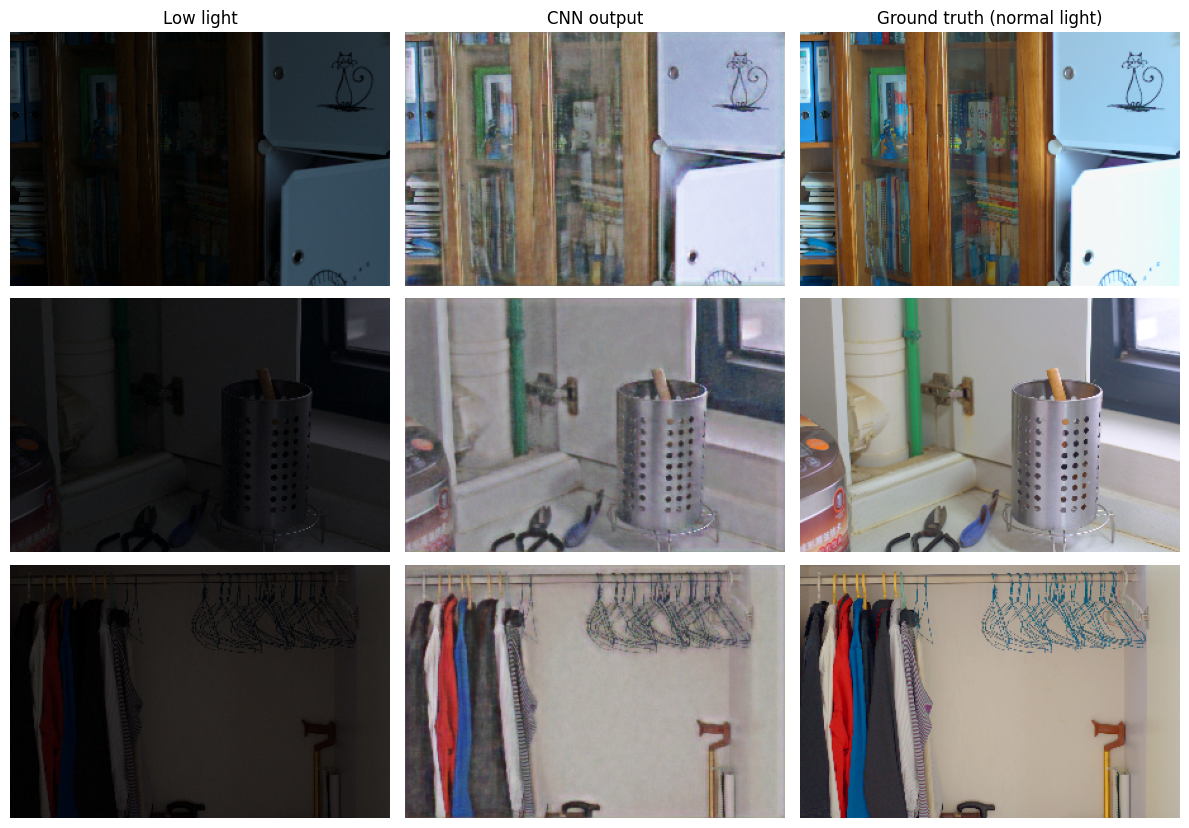

In [ ]:
# Final check on the 15 held-out test images
best_model = load_model(CNN_BEST_PATH, compile=False)
test_pred = best_model.predict(test_low_light_images, batch_size=8, verbose=0)

test_scores = {'input': score(test_normal_light_images, test_low_light_images),
               'cnn':   score(test_normal_light_images, test_pred)}
print('Input (no model):', test_scores['input'])
print('CNN             :', test_scores['cnn'])

# Saved so a final summary can compare all models side by side
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_test.json'), 'w') as f:
    json.dump(test_scores, f, indent=2)

show_results([test_low_light_images, test_pred, test_normal_light_images],
             ['Low light', 'CNN output', 'Ground truth (normal light)'])